# 14-4. 주요 모델 예측으로 만든 금 가격 전망

12시리즈에서 변수별로 선정한 모델이 만든 변수 예측을 앱의 TVP 금 가격 모델에 넣어 금 가격 전망을 만들고, 실제 가격과 비교해 정리한다.

- **입력**: 변수 6개의 예측. 각 예측 시점에서 그 시점 이전 데이터만 써서 변수별 선정 모델(12시리즈)이 만든 분위수다. `low`는 5%, `base`는 50%(중앙값), `high`는 95% 분위수다.
- **금 가격 계산**: 앱의 `gold_price_model`(TVP, 2016Q1부터 학습)이 변수 6개로 금 가격 YoY를 예측하고, 4분기 전 가격에 곱해 가격을 만든다. 14-3의 `TVP(예측 X)`와 같은 계산이고, 여기서는 low·high 시나리오까지 만든다.
- **예측 시점**: 2020Q1~2026Q1의 25개(13시리즈 PNG의 변수 공통 구간). 각 시점에서 4개 분기를 예측한다.
- **비교 가능한 행**: 실제 가격이 있는 분기만 오차를 계산한다(2026Q1 이후는 전망만 보인다).

## 1. 입력: 변수 예측(시나리오)

In [1]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
sys.path.insert(0, "../..")
import gold_price_model as app                                                # 앱의 TVP 금 가격 모델

SC = pd.read_csv("../../data/gold/gold_major_variables_forecast_model.csv", encoding="utf-8-sig")
price = pd.read_csv("../../data/gold/gold_price.csv", encoding="utf-8-sig").dropna(subset=["분기"]).set_index("분기")["실제가"]
VARS = ["X1", "X2", "X3", "X4", "X5", "X6"]
ALIAS = {"X1_l1": "X1", "X3_l1": "X3", "X5_l1": "X5", "X6_l1": "X6"}
full = SC.dropna().groupby("origin").size()
SC = SC[SC["origin"].isin(full[full == 12].index)]                       # 변수 6개가 모두 있는 예측 시점만 쓴다(앱의 예측시점과 같음)
ORIGINS = list(dict.fromkeys(SC["origin"]))
print(f"시나리오 {len(SC)}행: 예측 시점 {len(ORIGINS)}개 ({ORIGINS[0]} ~ {ORIGINS[-1]}) x 분기 4개 x 시나리오 3개")

2026-10-22 13:59:26.778 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


시나리오 300행: 예측 시점 25개 (2020Q1 ~ 2026Q1) x 분기 4개 x 시나리오 3개


In [2]:
SEL = pd.DataFrame([
    ["X1", "X1", "GARCH", "(0,0)", "원", "리샘플링"],
    ["X2", "X2", "AR단독", "(0,0)", "원", "자체"],
    ["X3", "X3", "GARCH", "(1,0)", "원", "리샘플링"],
    ["X4", "X4", "GARCH", "(0,0)", "원", "리샘플링"],
    ["X5", "X5", "GARCH", "(0,0)", "로그", "자체"],
    ["X6", "X6", "SV", "(1,0)", "원", "자체"],
], columns=["앱 변수", "변수", "모델", "(d, D)", "스케일", "구간"]).set_index("앱 변수")
display(SEL)
ex = SC[SC["origin"] == "2024Q4"].sort_values(["quarter", "scenario"], key=lambda s: s.map({"low": 0, "base": 1, "high": 2}) if s.name == "scenario" else s)
print("예: 2024Q4 예측 시점의 시나리오 (low=5%, base=50%, high=95% 분위수)")
display(ex.drop(columns="origin").round(4).set_index(["quarter", "scenario"]))

,변수,모델,"(d, D)",스케일,구간
앱 변수,,,,,
X1,X1,GARCH,"(0,0)",원,리샘플링
X2,X2,AR단독,"(0,0)",원,자체
X3,X3,GARCH,"(1,0)",원,리샘플링
X4,X4,GARCH,"(0,0)",원,리샘플링
X5,X5,GARCH,"(0,0)",로그,자체
X6,X6,SV,"(1,0)",원,자체


예: 2024Q4 예측 시점의 시나리오 (low=5%, base=50%, high=95% 분위수)


X1      X2         X3      X4      X5      X6
quarter scenario                                                     
2024Q4  low      -291.5071 -0.0097   912.7864  0.0179  0.0380  0.5803
        base       -3.4809 -0.0042  1126.3156  0.0569  0.0773  0.5884
        high      255.5548  0.0013  1382.8855  0.0944  0.1576  0.5965
2025Q1  low      -303.6061 -0.0144   572.5655  0.0118  0.0306  0.5722
        base      -10.1955 -0.0053  1131.0825  0.0654  0.0747  0.5884
        high      339.8113  0.0037  1653.7794  0.1317  0.1823  0.6046
2025Q2  low      -340.3156 -0.0162   577.9475  0.0006  0.0272  0.5696
        base      -12.5918 -0.0049  1131.0883  0.0692  0.0727  0.5884
        high      323.1453  0.0064  2315.3024  0.1772  0.1942  0.6072
2025Q3  low      -306.8460 -0.0163   247.6910  0.0074  0.0254  0.5649
        base      -13.4470 -0.0038  1130.3087  0.0706  0.0713  0.5884
        high      365.5489  0.0087  2479.2809  0.2279  0.2002  0.6119

## 2. 금 가격 전망 계산

In [3]:
CACHE = "../cache/cache_144_prices_df.pkl"
if os.path.exists(CACHE):
    P = pd.read_pickle(CACHE)
else:
    rows = []
    for o in ORIGINS:
        for sc in ["low", "base", "high"]:
            s = SC[(SC["origin"] == o) & (SC["scenario"] == sc)].sort_values("quarter")
            qs = [q.replace("Q", "-Q") for q in s["quarter"]]
            rv = {c: {q: float(v) for q, v in zip(qs, s[c])} for c in VARS}
            out = app.predict_final_gold_prices(rv, qs, ALIAS)               # 앱과 같은 계산(그 시점 직전까지의 데이터로 학습)
            for h, q in enumerate(qs, 1):
                rows.append({"예측 시점": o, "h": h, "분기": q.replace("-", ""), "시나리오": sc, "가격": out[q]})
    P = pd.DataFrame(rows).pivot(index=["예측 시점", "h", "분기"], columns="시나리오", values="가격").reset_index()
    P["실제"] = P["분기"].map(price)                                           # 실제 가격이 아직 없는 분기는 NaN
    P.to_pickle(CACHE)
P["구간 하한"], P["구간 상한"] = P[["low", "high"]].min(axis=1), P[["low", "high"]].max(axis=1)     # low가 base보다 높게 나오는 경우가 있어 작은 값~큰 값을 구간으로 본다
K = P[P["실제"].notna()].copy()
K["오차율(%)"] = (K["base"] / K["실제"] - 1) * 100
K["구간 안"] = (K["실제"] >= K["구간 하한"]) & (K["실제"] <= K["구간 상한"])
K["연도"] = K["예측 시점"].str[:4]
print(f"가격 행 {len(P)}개 중 실제 가격이 있는 행 {len(K)}개, 실제 가격이 아직 없는 행 {len(P) - len(K)}개(미래 전망)")

가격 행 100개 중 실제 가격이 있는 행 90개, 실제 가격이 아직 없는 행 10개(미래 전망)


## 3. 실제 가격과 비교

오차율은 base 전망 가격을 실제 가격과 비교한 값(base / 실제 - 1)이다.

In [4]:
by_h = K.groupby("h").agg(행=("오차율(%)", "size"), 평균오차율=("오차율(%)", "mean"), 절대오차율=("오차율(%)", lambda x: x.abs().mean()), 구간안비율=("구간 안", "mean"))
by_h["구간안비율"] *= 100
by_y = K.groupby("연도").agg(행=("오차율(%)", "size"), 평균오차율=("오차율(%)", "mean"), 절대오차율=("오차율(%)", lambda x: x.abs().mean()), 구간안비율=("구간 안", "mean"))
by_y["구간안비율"] *= 100
print("[예측 시점(h)별] 오차율 = base 가격 / 실제 가격 - 1")
display(by_h.round(1))
print("[예측 시점 연도별]")
display(by_y.round(1))
print(f"전체: 평균 오차율 {K['오차율(%)'].mean():.1f}%, 절대 오차율 {K['오차율(%)'].abs().mean():.1f}%, 구간 안 {K['구간 안'].mean() * 100:.0f}%")
QS = [q for q in price.index if q >= "2019Q4"]
pos = {q: i for i, q in enumerate(QS)}
BLUE, ORANGE, DARK = "#0072B2", "#E8590C", "#172033"

[예측 시점(h)별] 오차율 = base 가격 / 실제 가격 - 1


,행,평균오차율,절대오차율,구간안비율
h,,,,
1,24,-1.6,4.6,54.2
2,23,-3.0,7.6,52.2
3,22,-4.1,9.5,68.2
4,21,-5.5,10.3,71.4


[예측 시점 연도별]


,행,평균오차율,절대오차율,구간안비율
연도,,,,
2020,16,0.4,8.5,37.5
2021,16,1.4,10.5,50.0
2022,16,-3.1,4.2,81.2
2023,16,-1.8,4.4,100.0
2024,16,-12.0,12.2,56.2
2025,10,-7.2,7.4,30.0


전체: 평균 오차율 -3.5%, 절대 오차율 7.9%, 구간 안 61%


### 3-1. 예측 시점별 전망선

예측 시점마다 4분기짜리 base 선과 low~high 음영을 한 그림에 그린다.

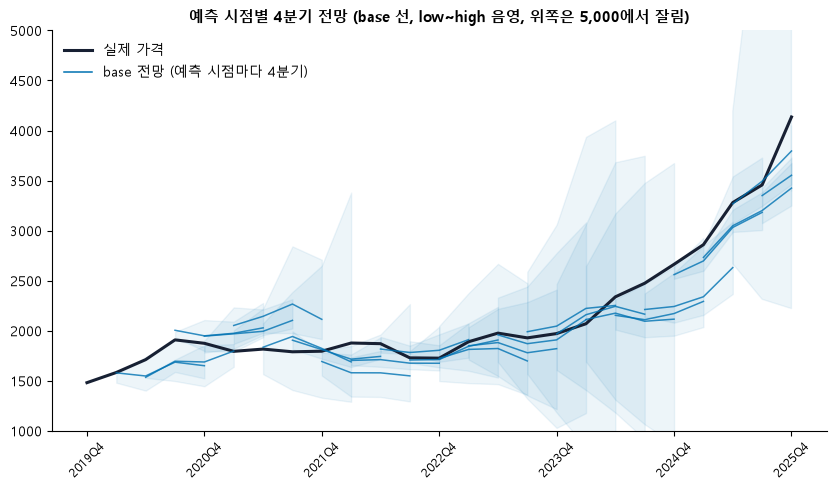

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(range(len(QS)), price[QS].values, color=DARK, linewidth=2.2, label="실제 가격")
for o in ORIGINS:
    t = P[(P["예측 시점"] == o) & P["분기"].isin(pos)].sort_values("h")
    if t.empty:
        continue
    xs = [pos[q] for q in t["분기"]]
    ax.fill_between(xs, t["구간 하한"], t["구간 상한"], color=BLUE, alpha=0.07)
    ax.plot(xs, t["base"], color=BLUE, linewidth=1.1, alpha=0.8)
ax.plot([], [], color=BLUE, linewidth=1.1, label="base 전망 (예측 시점마다 4분기)")
ax.set_ylim(1000, 5000)
ax.set_xticks(range(0, len(QS), 4))
ax.set_xticklabels(QS[::4], rotation=45, fontsize=8.5)
ax.set_title("예측 시점별 4분기 전망 (base 선, low~high 음영, 위쪽은 5,000에서 잘림)", fontsize=11, fontweight="bold")
ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 3-2. 구간 적중 히트맵

실제 가격이 low~high 안에 들어왔는지, 어느 방향으로 벗어났는지 본다.

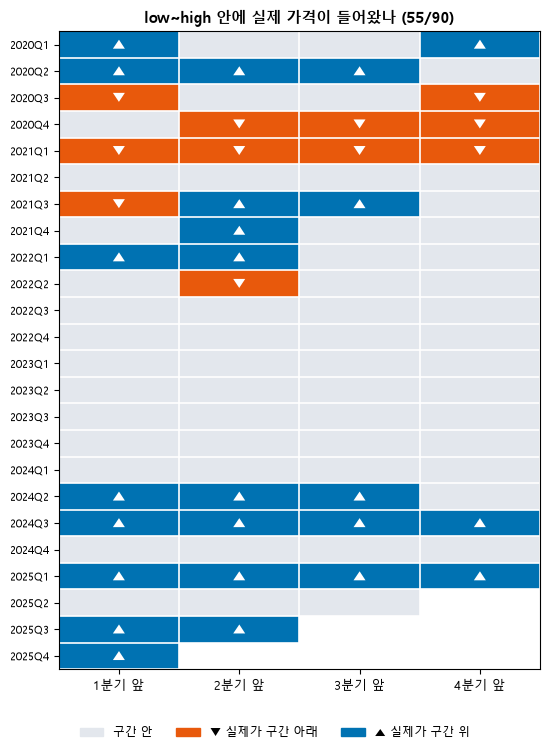

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
Z_ = P[P["실제"].notna()].copy()
Z_["판정"] = np.where(Z_["실제"] < Z_["구간 하한"], -1, np.where(Z_["실제"] > Z_["구간 상한"], 1, 0))
Hm = Z_.pivot(index="예측 시점", columns="h", values="판정")
fig, ax = plt.subplots(figsize=(5.6, 7.5))
ax.imshow(np.ma.masked_invalid(Hm.values), cmap=ListedColormap([ORANGE, "#E3E7ED", BLUE]), vmin=-1, vmax=1, aspect="auto")
for (r_, c_), v in np.ndenumerate(Hm.values):
    if np.isfinite(v) and v != 0:
        ax.text(c_, r_, "▼" if v < 0 else "▲", ha="center", va="center", color="white", fontsize=10)
for i in range(len(Hm) + 1):
    ax.axhline(i - 0.5, color="white", linewidth=1.2)
for i in range(5):
    ax.axvline(i - 0.5, color="white", linewidth=1.2)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{h}분기 앞" for h in range(1, 5)], fontsize=9)
ax.set_yticks(range(len(Hm)))
ax.set_yticklabels(Hm.index, fontsize=8)
ax.set_title(f"low~high 안에 실제 가격이 들어왔나 ({int((Hm == 0).sum().sum())}/{int(Hm.notna().sum().sum())})", fontsize=10.5, fontweight="bold")
fig.legend(handles=[Patch(color="#E3E7ED", label="구간 안"), Patch(color=ORANGE, label="▼ 실제가 구간 아래"), Patch(color=BLUE, label="▲ 실제가 구간 위")], loc="lower center", ncol=3, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 4. low~high 구간

In [7]:
K["아래"] = K["실제"] < K["구간 하한"]
K["위"] = K["실제"] > K["구간 상한"]
ok = ((K["low"] <= K["base"]) & (K["base"] <= K["high"]))
bnd = K.groupby("h").agg(구간안=("구간 안", "mean"), 실제가_아래=("아래", "mean"), 실제가_위=("위", "mean"))
bnd["low<base<high"] = ok.groupby(K["h"]).mean()
display((bnd * 100).round(0))
print(f"low<base<high 순서가 지켜진 비율 {ok.mean() * 100:.0f}% (변수마다 가격에 미치는 방향이 달라 low 시나리오 가격이 base보다 높게 나오는 경우가 있다)")

,구간안,실제가_아래,실제가_위,low<base<high
h,,,,
1,54.0,12.0,33.0,58.0
2,52.0,13.0,35.0,61.0
3,68.0,9.0,23.0,64.0
4,71.0,14.0,14.0,62.0


low<base<high 순서가 지켜진 비율 61% (변수마다 가격에 미치는 방향이 달라 low 시나리오 가격이 base보다 높게 나오는 경우가 있다)


## 5. 아직 실제 가격이 없는 분기의 전망

In [8]:
F = P[P["실제"].isna()]
F = F[F["예측 시점"].isin(["2025Q3", "2025Q4", "2026Q1"])]
print("실제 가격이 아직 없는 분기의 전망 (예측 시점이 2025Q3 이후)")
display(F[["예측 시점", "h", "분기", "low", "base", "high"]].round(0).set_index(["예측 시점", "분기"]).drop(columns="h"))

실제 가격이 아직 없는 분기의 전망 (예측 시점이 2025Q3 이후)


시나리오              low    base    high
예측 시점  분기                            
2025Q3 2026Q1  3365.0  3782.0  4897.0
       2026Q2  3693.0  4313.0  6140.0
2025Q4 2026Q1  3456.0  3949.0  4943.0
       2026Q2  3793.0  4537.0  6022.0
       2026Q3  4030.0  4792.0  6720.0
2026Q1 2026Q1  4383.0  4405.0  4582.0
       2026Q2  4730.0  5039.0  5507.0
       2026Q3  4919.0  5293.0  6467.0
       2026Q4  5821.0  6313.0  7927.0

## 결론

- **base 전망의 평균 절대 오차율은 7.9%이고 평균 오차율은 -3.5%**(실제보다 낮게)다. 비교한 90개 분기 전망 기준이다. 예측 시점이 멀수록 커져서 1분기 앞 4.6%, 2분기 앞 7.6%, 3분기 앞 9.5%, 4분기 앞 10.3%다.
- **연도별 편차가 크다**: 2022~2023년 시점은 절대 오차율 4.2~4.4%로 좋고 2023년은 구간 안 비율이 100%다. 반면 2024년 시점은 평균 -12.0%(절대 12.2%), 2025년 시점은 -7.2%로 실제보다 낮게 나온다. 가격이 가파르게 오른 2024~2025년 급등을 따라가지 못했다(14-3에서 선정 모델과 TVP 모두 같은 구간을 놓친 것과 같은 방향이다).
- **2020~2021년 시점은 부호가 반대**(2021년 시점 평균 +1.4%, 2021Q1 시점은 최대 +27%)로 실제보다 높게 나온 구간도 있다. TVP 학습 행이 16행부터 시작해 초반은 값이 불안정할 수 있다.
- **low~high(작은 값~큰 값) 안에 실제 가격이 들어온 비율은 61%**(1분기 앞 54%, 4분기 앞 71%)다. 빗나간 경우는 실제 가격이 위로 벗어난 것이 많다(1분기 앞 33%). 구간이 먼 시점일수록 넓어서 비율이 올라간다.
- **low<base<high 순서가 지켜진 비율은 61%**다. low 시나리오는 변수 6개를 모두 low로 넣는 것인데 변수마다 가격에 미치는 방향이 달라서 low 가격이 base보다 높게 나오는 경우가 있다(원인은 TVP 계수 구조로 추정하며 확인하지 않았다).
- **high 시나리오는 먼 시점에서 매우 넓어진다**: 변수 예측의 95% 분위수를 그대로 넣어서 high 가격이 base의 몇 배까지 나온다. 중앙값 기준 high/base는 1분기 앞 1.02배, 4분기 앞 1.12배이고 최대는 2.80배(2025Q2 시점의 2026Q1 전망)다. 앱 시나리오로 쓰기에는 5%·95%가 넓다고 느껴질 수 있다.
- **실제 가격이 아직 없는 분기의 전망**: 2026Q1 시점은 base가 2026Q2 5,039, 2026Q3 5,293, 2026Q4 6,313(low 5,821, high 7,927)이다.
- **해석 주의**: 변수 예측의 불확실성이 low·high에 반영되지만 TVP 모델 자체의 예측 오차는 이 구간에 들어 있지 않다. 비교한 예측 시점이 25개(분기 90개)로 작고, 2024~2025년 급등 구간의 영향이 크다.
